In [1]:
import pandas as pd
import seaborn as sns
from ast import literal_eval
from datasets import load_dataset
import matplotlib.pyplot as plt


dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].fillna('[]')
df['job_skills'] = df['job_skills'].apply(literal_eval)

c:\Users\Windows 11\miniconda3\envs\python_project\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df_US_DE = df[(df['job_title_short'] == 'Data Engineer') & (df['job_country'] == 'United States')]

In [3]:
df_skills = df_US_DE.explode('job_skills')

In [ ]:
df_skills_count = df_skills.groupby(['job_skills']).size()

df_skills_count = df_skills_count.reset_index(name='skill_count')

df_skills_count.sort_values(by='skill_count', ascending=False, inplace=True)

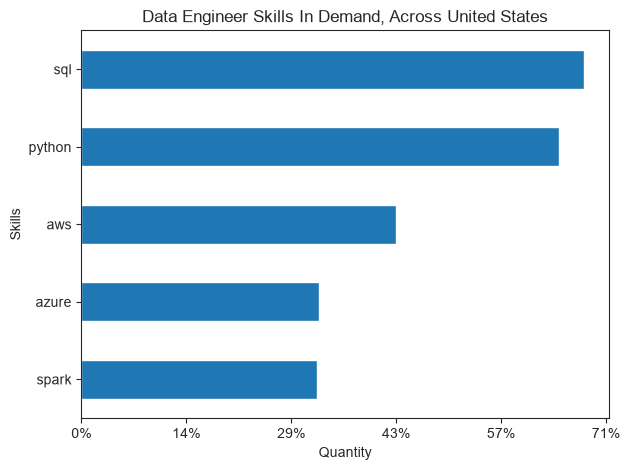

In [37]:
from matplotlib.ticker import PercentFormatter
total_postings = len(df_US_DE)
fig, ax = plt.subplots(1, 1)
df_plot = df_skills_count.head(5)
df_plot[::-1].plot(kind='barh', x='job_skills', y='skill_count', title='Data Engineer Skills In Demand, Across United States', legend=False, ax=ax)
ax.set_ylabel('Skills')
ax.set_xlabel('Quantity')
ax.xaxis.set_major_formatter(PercentFormatter(xmax=total_postings))
fig.tight_layout()
plt.show()

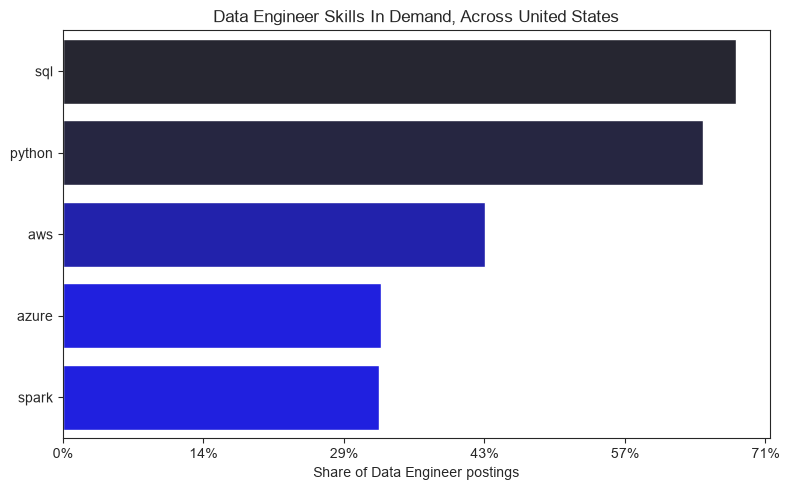

In [ ]:
from matplotlib.ticker import PercentFormatter

total_postings = len(df_US_DE)

fig, ax = plt.subplots(figsize=(8, 5))
sns.set_style('ticks')

sns.barplot(
    data=df_plot,
    x='skill_count', y='job_skills',
    hue='skill_count', palette='dark:b_r', legend=False,
    ax=ax 
)

ax.set_title('Data Engineer Skills In Demand, Across United States')
ax.set_xlabel('Share of Data Engineer postings')
ax.set_ylabel('')
ax.xaxis.set_major_formatter(PercentFormatter(xmax=total_postings))

fig.tight_layout()
plt.show()